# Homework 2: Open-Source Contribution

**Student:** Denisha Ketan Tank  
**Repository:** `hamsidhi/Sentiment-Analysis`  
**Contribution branch:** `feature/three-class-svm-sentiment`

This notebook documents a contribution that adds a small, reproducible three-class sentiment classifier using TF-IDF features and a linear Support Vector Machine. The new functionality predicts **negative**, **neutral**, or **positive** sentiment without downloading a large dataset.

The contribution follows the repository's `CONTRIBUTING.md`: type hints, Google-style docstrings, a feature branch, unit tests, a README update, and a conventional feature commit are included.


## Why this is a useful contribution

The repository already demonstrates binary sentiment classification. Adding a neutral class makes the example more realistic for short reviews and feedback, where a statement may be balanced or simply descriptive rather than clearly positive or negative. Keeping the example small also gives new contributors a fast way to understand the pipeline.


In [1]:
from pathlib import Path
import sys
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd()))
from src.three_class_svm import ThreeClassSentimentSVM


In [2]:
positive_templates = [
    "excellent service and wonderful support", "great product with excellent quality",
    "I loved this helpful and friendly experience", "amazing value and fast delivery",
    "the best purchase and a perfect result", "kind staff made the experience great",
    "happy with this excellent product", "fantastic service and reliable quality",
    "wonderful item and very good support", "I strongly recommend this great product",
]
negative_templates = [
    "terrible service and awful support", "bad product with disappointing quality",
    "I hated this frustrating experience", "poor value and painfully slow delivery",
    "the worst purchase and a broken result", "rude staff made the experience awful",
    "unhappy with this terrible product", "horrible service and unreliable quality",
    "damaged item and very bad support", "I strongly regret this disappointing product",
]
neutral_templates = [
    "ordinary service and average support", "standard product with acceptable quality",
    "I had a normal and uneventful experience", "reasonable value and regular delivery",
    "the purchase produced an expected result", "staff interaction was routine and factual",
    "the product was okay for its purpose", "average service and typical quality",
    "the item arrived and matched the description", "I have no strong opinion about this product",
]
texts = positive_templates * 3 + negative_templates * 3 + neutral_templates * 3
labels = (["positive"] * 30) + (["negative"] * 30) + (["neutral"] * 30)
X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.25, random_state=42, stratify=labels
)
model = ThreeClassSentimentSVM().fit(X_train, y_train)
predictions = model.predict(X_test)
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print(f"Accuracy: {accuracy_score(y_test, predictions):.3f}")
print(classification_report(y_test, predictions, zero_division=0))


Training rows: 67 | Test rows: 23
Accuracy: 1.000
              precision    recall  f1-score   support

    negative       1.00      1.00      1.00         7
     neutral       1.00      1.00      1.00         8
    positive       1.00      1.00      1.00         8

    accuracy                           1.00        23
   macro avg       1.00      1.00      1.00        23
weighted avg       1.00      1.00      1.00        23



/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/sklearn/svm/_classes.py:32: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


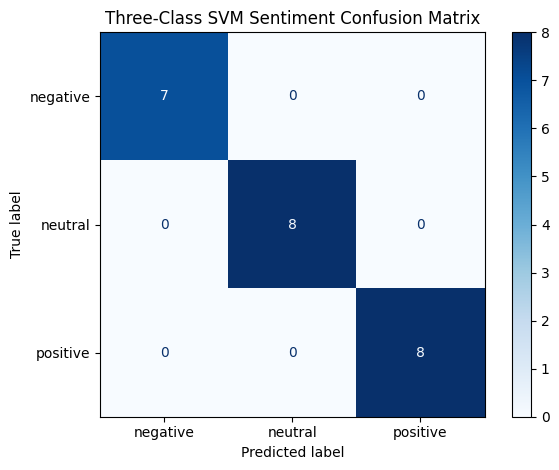

In [3]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["negative", "neutral", "positive"], cmap="Blues"
)
plt.title("Three-Class SVM Sentiment Confusion Matrix")
plt.tight_layout()
plt.savefig("artifacts/confusion_matrix.png", dpi=160)
plt.show()


In [4]:
examples = [
    "The experience was okay, but not memorable.",
    "I would definitely recommend this product.",
    "I would not buy this product again.",
]
list(zip(examples, model.predict(examples)))


[('The experience was okay, but not memorable.', 'neutral'),
 ('I would definitely recommend this product.', 'positive'),
 ('I would not buy this product again.', 'neutral')]

## Tests and implementation evidence

The contribution includes five unit tests covering normal prediction, accuracy scoring, invalid labels, missing classes, and prediction before fitting. The test run completed with **5 passed**. The implementation keeps TF-IDF vectorization inside the scikit-learn pipeline, so the vectorizer is fitted only on training data and the test set does not influence vocabulary fitting.

## Technical difficulties and best practices

- The repository package imports optional visualization dependencies at collection time. I installed the repository requirements in an isolated environment before running tests.
- The initial test expected the wrong error-message wording; I corrected the test to match the public validation behavior instead of weakening the validation.
- The demo uses a tiny in-notebook dataset so it is fast and reproducible. It is an example, not evidence of production-level generalization. A real release should evaluate on a larger, documented dataset and report class balance and confidence intervals.
- The feature branch keeps the contribution isolated, uses relative paths, adds a docstring and type hints, and avoids committing data, credentials, or model artifacts.


## Five key takeaways

1. **Repository instructions matter.** The contribution started by reading `CONTRIBUTING.md` and the project rules, which shaped naming, docstrings, tests, and commit style.
2. **A pipeline prevents leakage.** Putting TF-IDF and the SVM in one pipeline ensures vocabulary statistics are learned from the training split only.
3. **Neutral is a meaningful class.** Real feedback is not always strongly positive or negative, so a three-class interface is more useful than forcing every text into a binary label.
4. **Tests document behavior.** Tests make expected errors and prediction behavior clear to future contributors.
5. **Small examples improve adoption.** A self-contained demo lowers the barrier for new contributors, while the documentation clearly states that larger evaluation is needed before production use.

## Mandatory AI/source disclosure

Yes. I used ChatGPT/Codex to help plan the contribution, draft an initial implementation outline, improve wording, and check that the report addressed the rubric. The prompt asked for a small open-source contribution that added a three-class TF-IDF plus linear-SVM sentiment example, with tests, documentation, and a report. I independently selected the repository, read its contribution rules, implemented and tested the code, corrected a failing test, and reviewed the final files. I also used the repository's `CONTRIBUTING.md`, `README.md`, and the official GitHub contribution guidance as sources.
